<a href="https://colab.research.google.com/github/asrigrisha-2006/ML_AP24110011682/blob/main/mini_project_movie_recommendation_system_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Recommendation System

The Movie Recommendation System suggests movies to users based on their interests and previous ratings.

**Dataset:** MovieLens Latest Small

**Technologies Used:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

**Algorithms Used:**
1. Popularity-Based Filtering
2. Content-Based Filtering
3. KNN Collaborative Filtering
4. Singular Value Decomposition (SVD)

**Evaluation Metrics:**
- RMSE
- Precision@K
- Recall@K
- NDCG@K

**Objective:**

To develop a movie recommendation system that suggests relevant movies to users and compares different recommendation techniques.

In [1]:
## 1. Dataset Extraction
import os
import zipfile
from google.colab import files

dataset_folder = "/content/ml-latest-small"

if not os.path.exists(dataset_folder):

    uploaded = files.upload()

    zip_files = [
        name for name in uploaded.keys()
        if name.endswith(".zip")
    ]

    if not zip_files:
        raise FileNotFoundError("Please upload the MovieLens ZIP file.")

    zip_path = "/content/" + zip_files[0]

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/")

print("Dataset extracted successfully!")
print(os.listdir(dataset_folder))

Saving ml-latest-small.zip to ml-latest-small (1).zip
Dataset extracted successfully!
['links.csv', 'ratings.csv', 'movies.csv', 'README.txt', 'tags.csv']


In [2]:
## 2. Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import csr_matrix

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import TruncatedSVD

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
## 3. Loading the Dataset

data_path = "/content/ml-latest-small/"

movies = pd.read_csv(data_path + "movies.csv")
ratings = pd.read_csv(data_path + "ratings.csv")
tags = pd.read_csv(data_path + "tags.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)

display(movies.head())
display(ratings.head())
display(tags.head())

Movies shape: (9742, 3)
Ratings shape: (100836, 4)
Tags shape: (3683, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [5]:
## 4. Data Preprocessing
print("Duplicate movies:", movies.duplicated().sum())
print("Duplicate ratings:", ratings.duplicated().sum())
print("Duplicate tags:", tags.duplicated().sum())

movies = movies.drop_duplicates(subset="movieId")

ratings = ratings.drop_duplicates(
    subset=["userId", "movieId"]
)

ratings = ratings[
    ratings["rating"].between(0.5, 5.0)
].copy()

valid_movie_ids = set(movies["movieId"])

ratings = ratings[
    ratings["movieId"].isin(valid_movie_ids)
].copy()

tags = tags[
    tags["movieId"].isin(valid_movie_ids)
].copy()

movies = movies.reset_index(drop=True)

print("\nPreprocessing completed!")

print("Movies:", len(movies))
print("Ratings:", len(ratings))
print("Tags:", len(tags))


Duplicate movies: 0
Duplicate ratings: 0
Duplicate tags: 0

Preprocessing completed!
Movies: 9742
Ratings: 100836
Tags: 3683


In [6]:
#Check missing values and dataset information
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

print("\nMissing values in Tags:")
print(tags.isnull().sum())

print("\nUnique users:", ratings["userId"].nunique())
print("Unique movies rated:", ratings["movieId"].nunique())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

Missing values in Movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in Ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in Tags:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Unique users: 610
Unique movies rated: 9724

Rating distribution:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


## 5. Exploratory Data Analysis

Analyze the dataset to understand user ratings, movie popularity and genre distribution.

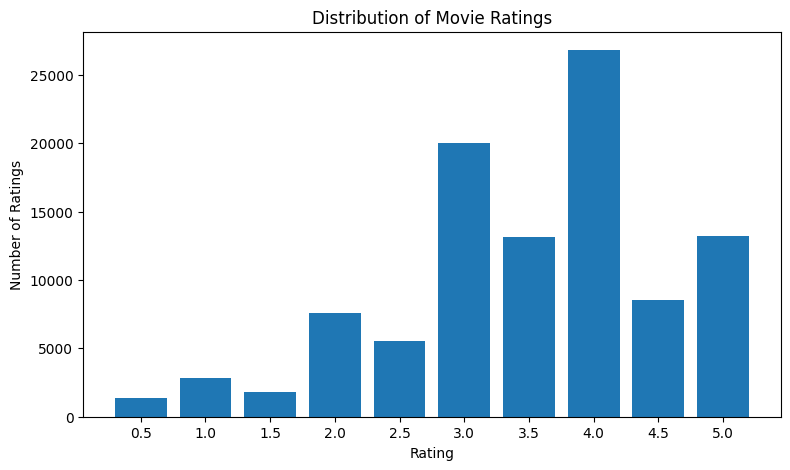

In [7]:
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    rating_counts.index.astype(str),
    rating_counts.values
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

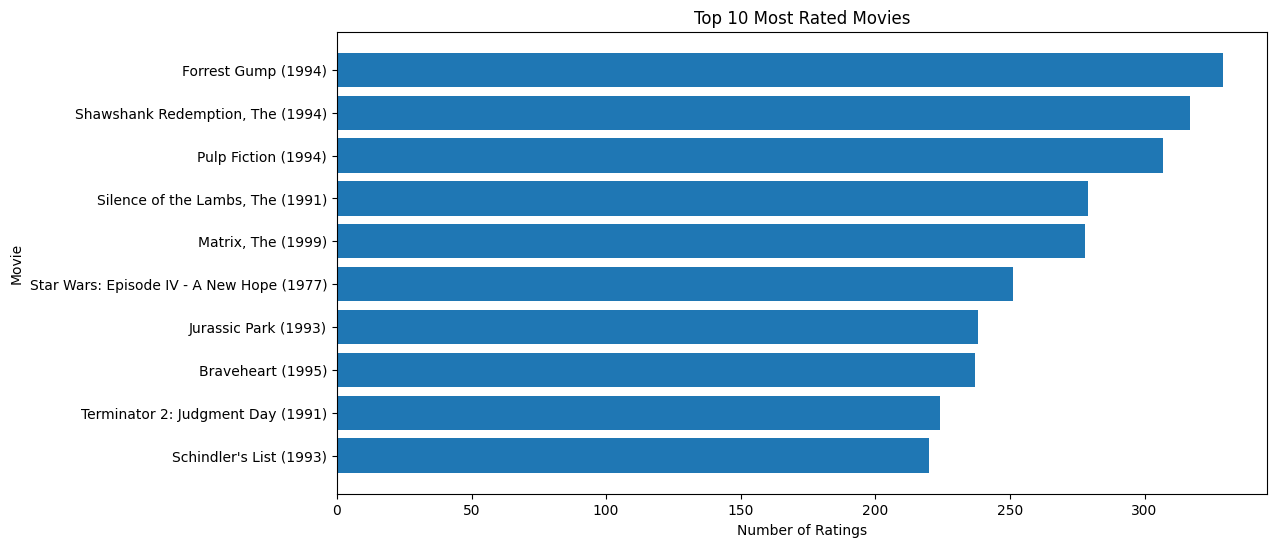

In [8]:
movie_rating_counts = ratings.groupby(
    "movieId"
).size().reset_index(name="rating_count")

most_rated = movie_rating_counts.merge(
    movies[["movieId", "title"]],
    on="movieId"
)

most_rated = most_rated.sort_values(
    "rating_count",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    most_rated["title"],
    most_rated["rating_count"]
)

plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.title("Top 10 Most Rated Movies")

plt.gca().invert_yaxis()
plt.show()

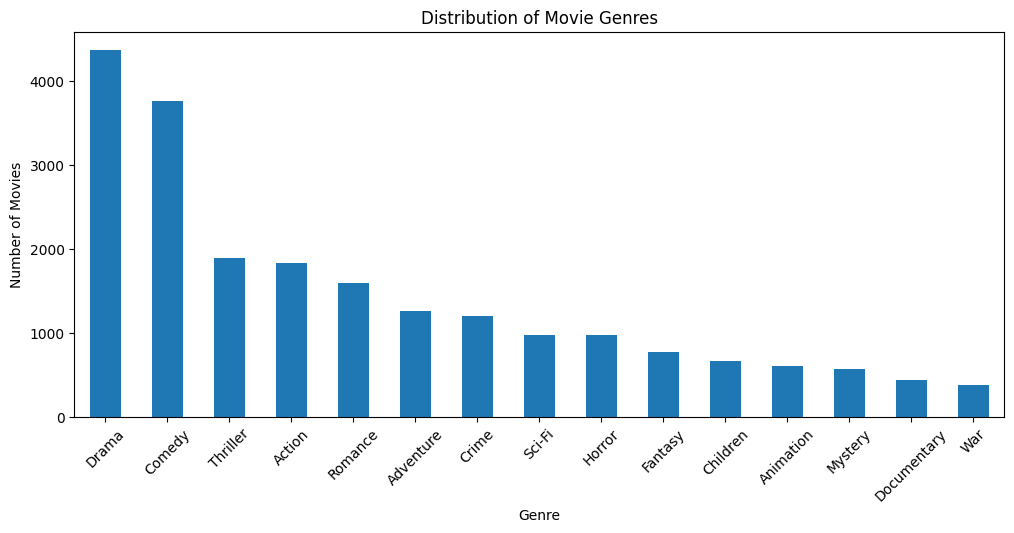

In [9]:
genre_counts = movies["genres"].str.split("|").explode()

genre_counts = genre_counts[
    genre_counts != "(no genres listed)"
]

genre_counts.value_counts().head(15).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)
plt.show()

Popularity-Based Recommendation

In [10]:
movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

popular_movies = movie_stats.merge(
    movies[["movieId", "title"]],
    on="movieId"
)

popular_movies = popular_movies[
    popular_movies["rating_count"] >= 50
]

popular_movies = popular_movies.sort_values(
    ["average_rating", "rating_count"],
    ascending=False
)

display(
    popular_movies[
        ["title", "average_rating", "rating_count"]
    ].head(10)
)

,title,average_rating,rating_count
277,"Shawshank Redemption, The (1994)",4.429022,317
659,"Godfather, The (1972)",4.289062,192
2224,Fight Club (1999),4.272936,218
974,Cool Hand Luke (1967),4.271930,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.268041,97
686,Rear Window (1954),4.261905,84
921,"Godfather: Part II, The (1974)",4.259690,129
6298,"Departed, The (2006)",4.252336,107
913,Goodfellas (1990),4.250000,126
694,Casablanca (1942),4.240000,100


Train-Test Split

In [11]:
ratings_train, ratings_test = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(ratings_train))
print("Testing records:", len(ratings_test))

Training records: 80668
Testing records: 20168


KNN Collaborative Filtering

In [13]:

#User-movie matrixall_users = sorted(ratings_train["userId"].unique())

all_movie_ids = sorted(movies["movieId"].unique())

user_movie_matrix = ratings_train.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

user_movie_matrix = user_movie_matrix.reindex(
    index=all_users,
    columns=all_movie_ids
)

user_movie_matrix = user_movie_matrix.fillna(0)

print("User-Movie Matrix Shape:", user_movie_matrix.shape)

display(user_movie_matrix.iloc[:5, :10])

User-Movie Matrix Shape: (610, 9742)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
#Train the KNN model
item_user_matrix = user_movie_matrix.T

item_user_sparse = csr_matrix(
    item_user_matrix.values
)

knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=min(11, len(all_movie_ids))
)

knn_model.fit(item_user_sparse)

knn_distances, knn_indices = knn_model.kneighbors(
    item_user_sparse
)

knn_movie_to_index = {
    movie_id: index
    for index, movie_id in enumerate(all_movie_ids)
}

print("KNN model trained successfully!")

KNN model trained successfully!


In [15]:
#Create KNN recommendation function
def knn_recommend_for_user(user_id, top_n=10):

    if user_id not in user_movie_matrix.index:
        return []

    user_ratings = user_movie_matrix.loc[user_id]

    liked_movies = user_ratings[
        user_ratings >= 4.0
    ]

    scores = {}

    for movie_id, rating in liked_movies.items():

        movie_index = knn_movie_to_index[movie_id]

        for distance, neighbor_index in zip(
            knn_distances[movie_index],
            knn_indices[movie_index]
        ):

            neighbor_id = all_movie_ids[neighbor_index]

            if neighbor_id == movie_id:
                continue

            if user_ratings[neighbor_id] == 0:

                similarity = max(0, 1 - distance)

                scores[neighbor_id] = (
                    scores.get(neighbor_id, 0)
                    + similarity * rating
                )

    sorted_movies = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [
        movie_id
        for movie_id, score in sorted_movies[:top_n]
    ]

In [16]:
#Test KNN recommendations
knn_recommendations = knn_recommend_for_user(
    user_id=1,
    top_n=10
)

knn_result = movies.set_index("movieId").loc[
    knn_recommendations
].reset_index()

print("KNN Recommendations for User 1:")

display(knn_result[["title", "genres"]])

KNN Recommendations for User 1:


,title,genres
0,Who Framed Roger Rabbit? (1988),Adventure|Animation|Children|Comedy|Crime|Fant...
1,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure
2,True Lies (1994),Action|Adventure|Comedy|Romance|Thriller
3,Men in Black (a.k.a. MIB) (1997),Action|Comedy|Sci-Fi
4,Indiana Jones and the Temple of Doom (1984),Action|Adventure|Fantasy
5,"Breakfast Club, The (1985)",Comedy|Drama
6,For Your Eyes Only (1981),Action|Adventure|Thriller
7,"Fifth Element, The (1997)",Action|Adventure|Comedy|Sci-Fi
8,"Sixth Sense, The (1999)",Drama|Horror|Mystery
9,"Shawshank Redemption, The (1994)",Crime|Drama


SVD Matrix Factorization

In [17]:
#Prepare the rating matrix
global_mean = ratings_train["rating"].mean()

rating_matrix = user_movie_matrix.values.astype(float)

observed_mask = rating_matrix > 0

centered_matrix = rating_matrix.copy()

centered_matrix[observed_mask] -= global_mean

print("Rating matrix prepared for SVD!")

print("Matrix shape:", centered_matrix.shape)
print("Global mean rating:", round(global_mean, 3))

Rating matrix prepared for SVD!
Matrix shape: (610, 9742)
Global mean rating: 3.503


In [18]:
#Train SVD model
n_components = min(
    50,
    min(centered_matrix.shape) - 1
)

svd_model = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

user_factors = svd_model.fit_transform(
    centered_matrix
)

predicted_matrix = (
    user_factors @ svd_model.components_
) + global_mean

predicted_matrix = np.clip(
    predicted_matrix,
    0.5,
    5.0
)

print("SVD model trained successfully!")

print(
    "Explained variance ratio:",
    round(svd_model.explained_variance_ratio_.sum(), 4)
)

SVD model trained successfully!
Explained variance ratio: 0.4955


In [19]:
#Create SVD recommendation function
user_to_index = {
    user_id: index
    for index, user_id in enumerate(all_users)
}

movie_to_index = {
    movie_id: index
    for index, movie_id in enumerate(all_movie_ids)
}


def svd_recommend_for_user(user_id, top_n=10):

    if user_id not in user_to_index:
        return []

    user_index = user_to_index[user_id]

    scores = predicted_matrix[user_index].copy()

    seen_movies = user_movie_matrix.loc[user_id]

    for movie_id, rating in seen_movies.items():

        if rating > 0:
            scores[movie_to_index[movie_id]] = -1

    top_indices = np.argsort(scores)[::-1]

    recommendations = []

    for index in top_indices:

        if scores[index] < 0:
            continue

        recommendations.append(
            all_movie_ids[index]
        )

        if len(recommendations) == top_n:
            break

    return recommendations

In [20]:
#Test SVD recommendations
svd_recommendations = svd_recommend_for_user(
    user_id=1,
    top_n=10
)

svd_result = movies.set_index("movieId").loc[
    svd_recommendations
].reset_index()

print("SVD Recommendations for User 1:")

display(svd_result[["title", "genres"]])

SVD Recommendations for User 1:


,title,genres
0,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure
1,Jaws (1975),Action|Horror
2,"Godfather, The (1972)",Crime|Drama
3,Terminator 2: Judgment Day (1991),Action|Sci-Fi
4,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy
5,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi
6,Good Will Hunting (1997),Drama|Romance
7,Big (1988),Comedy|Drama|Fantasy|Romance
8,American History X (1998),Crime|Drama
9,Indiana Jones and the Temple of Doom (1984),Action|Adventure|Fantasy


Content-Based Filtering

In [21]:
tag_text = tags.groupby("movieId")["tag"].apply(
    lambda x: " ".join(x.astype(str))
).reset_index()

tag_text.columns = ["movieId", "tags"]

movie_features = movies.merge(
    tag_text,
    on="movieId",
    how="left"
)

movie_features["tags"] = movie_features["tags"].fillna("")

movie_features["content"] = (
    movie_features["genres"].str.replace(
        "|", " ", regex=False
    )
    + " "
    + movie_features["tags"]
)

movie_features["content"] = movie_features[
    "content"
].str.replace(
    "(no genres listed)", "", regex=False
)

print("Movie features prepared!")

display(
    movie_features[
        ["title", "genres", "tags", "content"]
    ].head()
)

Movie features prepared!


,title,genres,tags,content
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,pixar pixar fun,Adventure Animation Children Comedy Fantasy pi...
1,Jumanji (1995),Adventure|Children|Fantasy,fantasy magic board game Robin Williams game,Adventure Children Fantasy fantasy magic board...
2,Grumpier Old Men (1995),Comedy|Romance,moldy old,Comedy Romance moldy old
3,Waiting to Exhale (1995),Comedy|Drama|Romance,,Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy,pregnancy remake,Comedy pregnancy remake


In [22]:
#TF-IDF vectorization
tfidf = TfidfVectorizer(
    stop_words="english"
)

tfidf_matrix = tfidf.fit_transform(
    movie_features["content"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

print("TF-IDF feature extraction completed!")

TF-IDF matrix shape: (9742, 1675)
TF-IDF feature extraction completed!


In [23]:
#Train content similarity model
content_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

content_knn.fit(tfidf_matrix)

movie_id_to_index = {
    movie_id: index
    for index, movie_id in enumerate(
        movie_features["movieId"]
    )
}

print("Content-Based model trained successfully!")

Content-Based model trained successfully!


In [24]:
#Recommend similar movies
def recommend_similar_movies(movie_title, top_n=10):

    matches = movie_features[
        movie_features["title"].str.contains(
            movie_title,
            case=False,
            regex=False
        )
    ]

    if matches.empty:
        print("Movie not found!")
        return

    selected_movie = matches.iloc[0]

    movie_index = movie_id_to_index[
        selected_movie["movieId"]
    ]

    distances, indices = content_knn.kneighbors(
        tfidf_matrix[movie_index],
        n_neighbors=min(top_n + 1, len(movies))
    )

    recommendations = []

    for distance, index in zip(
        distances[0],
        indices[0]
    ):

        if index == movie_index:
            continue

        recommendations.append({
            "Movie": movie_features.iloc[index]["title"],
            "Similarity": round(float(1 - distance), 4)
        })

    result = pd.DataFrame(recommendations)

    print("Selected Movie:", selected_movie["title"])

    display(result.head(top_n))

    return result.head(top_n)

In [25]:
recommend_similar_movies("Toy Story", 10)

Selected Movie: Toy Story (1995)


,Movie,Similarity
0,"Bug's Life, A (1998)",0.8622
1,Toy Story 2 (1999),0.6440
2,Guardians of the Galaxy 2 (2017),0.3677
3,"Monsters, Inc. (2001)",0.3579
4,Asterix and the Vikings (Astérix et les Viking...,0.3579
5,Moana (2016),0.3579
6,Turbo (2013),0.3579
7,"Tale of Despereaux, The (2008)",0.3579
8,Antz (1998),0.3579
9,"Emperor's New Groove, The (2000)",0.3579


,Movie,Similarity
0,"Bug's Life, A (1998)",0.8622
1,Toy Story 2 (1999),0.6440
2,Guardians of the Galaxy 2 (2017),0.3677
3,"Monsters, Inc. (2001)",0.3579
4,Asterix and the Vikings (Astérix et les Viking...,0.3579
5,Moana (2016),0.3579
6,Turbo (2013),0.3579
7,"Tale of Despereaux, The (2008)",0.3579
8,Antz (1998),0.3579
9,"Emperor's New Groove, The (2000)",0.3579


Recommendation functions for evaluation

In [26]:
#Popularity recommendation function
popularity_stats = ratings_train.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

popularity_train = popularity_stats[
    popularity_stats["rating_count"] >= 20
].sort_values(
    ["average_rating", "rating_count"],
    ascending=False
)

popular_movie_ids = popularity_train["movieId"].tolist()


def popularity_recommend_for_user(user_id, top_n=10):

    if user_id not in user_movie_matrix.index:
        return []

    seen_movies = set(
        user_movie_matrix.loc[user_id][
            user_movie_matrix.loc[user_id] > 0
        ].index
    )

    recommendations = [
        movie_id
        for movie_id in popular_movie_ids
        if movie_id not in seen_movies
    ]

    return recommendations[:top_n]


print("Popularity recommendation function ready!")

Popularity recommendation function ready!


In [27]:
#Content-based recommendation function
def content_recommend_for_user(user_id, top_n=10):

    if user_id not in user_movie_matrix.index:
        return []

    user_ratings = user_movie_matrix.loc[user_id]

    liked_movies = user_ratings[
        user_ratings >= 4.0
    ].index.tolist()

    if len(liked_movies) == 0:
        return popularity_recommend_for_user(
            user_id, top_n
        )

    liked_indices = [
        movie_id_to_index[movie_id]
        for movie_id in liked_movies
        if movie_id in movie_id_to_index
    ]

    if len(liked_indices) == 0:
        return popularity_recommend_for_user(
            user_id, top_n
        )

    user_profile = tfidf_matrix[
        liked_indices
    ].mean(axis=0)

    user_profile = np.asarray(
        user_profile
    ).reshape(1, -1)

    similarities = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).flatten()

    seen_movies = set(
        user_ratings[user_ratings > 0].index
    )

    for movie_id in seen_movies:

        similarities[
            movie_id_to_index[movie_id]
        ] = -1

    top_indices = np.argsort(
        similarities
    )[::-1]

    recommendations = []

    for index in top_indices:

        movie_id = movie_features.iloc[
            index
        ]["movieId"]

        if movie_id not in seen_movies:
            recommendations.append(movie_id)

        if len(recommendations) == top_n:
            break

    return recommendations

In [28]:
#Test all recommendation methods
test_user = 1

print("Popularity-Based Recommendations")

pop_ids = popularity_recommend_for_user(test_user, 5)
display(movies.set_index("movieId").loc[pop_ids][["title", "genres"]])

print("Content-Based Recommendations")

content_ids = content_recommend_for_user(test_user, 5)
display(movies.set_index("movieId").loc[content_ids][["title", "genres"]])

print("KNN Recommendations")

knn_ids = knn_recommend_for_user(test_user, 5)
display(movies.set_index("movieId").loc[knn_ids][["title", "genres"]])

print("SVD Recommendations")

svd_ids = svd_recommend_for_user(test_user, 5)
display(movies.set_index("movieId").loc[svd_ids][["title", "genres"]])

Popularity-Based Recommendations


,title,genres
movieId,,
318,"Shawshank Redemption, The (1994)",Crime|Drama
922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance
898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance
933,To Catch a Thief (1955),Crime|Mystery|Romance|Thriller
78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX


Content-Based Recommendations


,title,genres
movieId,,
117646,Dragonheart 2: A New Beginning (2000),Action|Adventure|Comedy|Drama|Fantasy|Thriller
55116,"Hunting Party, The (2007)",Action|Adventure|Comedy|Drama|Thriller
5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama
6990,The Great Train Robbery (1978),Action|Adventure|Comedy|Crime|Drama
546,Super Mario Bros. (1993),Action|Adventure|Children|Comedy|Fantasy|Sci-Fi


KNN Recommendations


,title,genres
movieId,,
2987,Who Framed Roger Rabbit? (1988),Adventure|Animation|Children|Comedy|Crime|Fant...
1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure
380,True Lies (1994),Action|Adventure|Comedy|Romance|Thriller
1580,Men in Black (a.k.a. MIB) (1997),Action|Comedy|Sci-Fi
2115,Indiana Jones and the Temple of Doom (1984),Action|Adventure|Fantasy


SVD Recommendations


,title,genres
movieId,,
1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure
1387,Jaws (1975),Action|Horror
858,"Godfather, The (1972)",Crime|Drama
589,Terminator 2: Judgment Day (1991),Action|Sci-Fi
2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy


Model evaluation

In [29]:
#Calculate Precision, Recall and NDCG
def calculate_ranking_metrics(
    recommendation_function,
    k=10
):

    precisions = []
    recalls = []
    ndcgs = []

    for user_id, user_data in ratings_test.groupby("userId"):

        relevant_movies = set(
            user_data[
                user_data["rating"] >= 4.0
            ]["movieId"]
        )

        if len(relevant_movies) == 0:
            continue

        recommended_movies = recommendation_function(
            user_id, k
        )

        hits = [
            1 if movie_id in relevant_movies else 0
            for movie_id in recommended_movies
        ]

        precision = sum(hits) / k

        recall = sum(hits) / len(relevant_movies)

        dcg = sum(
            hit / np.log2(position + 2)
            for position, hit in enumerate(hits)
        )

        ideal_hits = min(
            len(relevant_movies), k
        )

        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        precisions.append(precision)
        recalls.append(recall)
        ndcgs.append(ndcg)

    return {
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs)
    }


print("Ranking evaluation function created!")

Ranking evaluation function created!


In [30]:
#Compare recommendation models
model_functions = {
    "Popularity-Based": popularity_recommend_for_user,
    "Content-Based": content_recommend_for_user,
    "KNN Collaborative": knn_recommend_for_user,
    "SVD": svd_recommend_for_user
}

comparison_results = []

for model_name, recommendation_function in model_functions.items():

    print("Evaluating:", model_name)

    metrics = calculate_ranking_metrics(
        recommendation_function,
        k=10
    )

    comparison_results.append({
        "Model": model_name,
        **metrics
    })

comparison_df = pd.DataFrame(
    comparison_results
)

comparison_df = comparison_df.round(4)

display(comparison_df)

Evaluating: Popularity-Based
Evaluating: Content-Based
Evaluating: KNN Collaborative
Evaluating: SVD


,Model,Precision@10,Recall@10,NDCG@10
0,Popularity-Based,0.0311,0.0262,0.0443
1,Content-Based,0.0043,0.0045,0.0048
2,KNN Collaborative,0.1815,0.1732,0.2443
3,SVD,0.1437,0.1298,0.2034


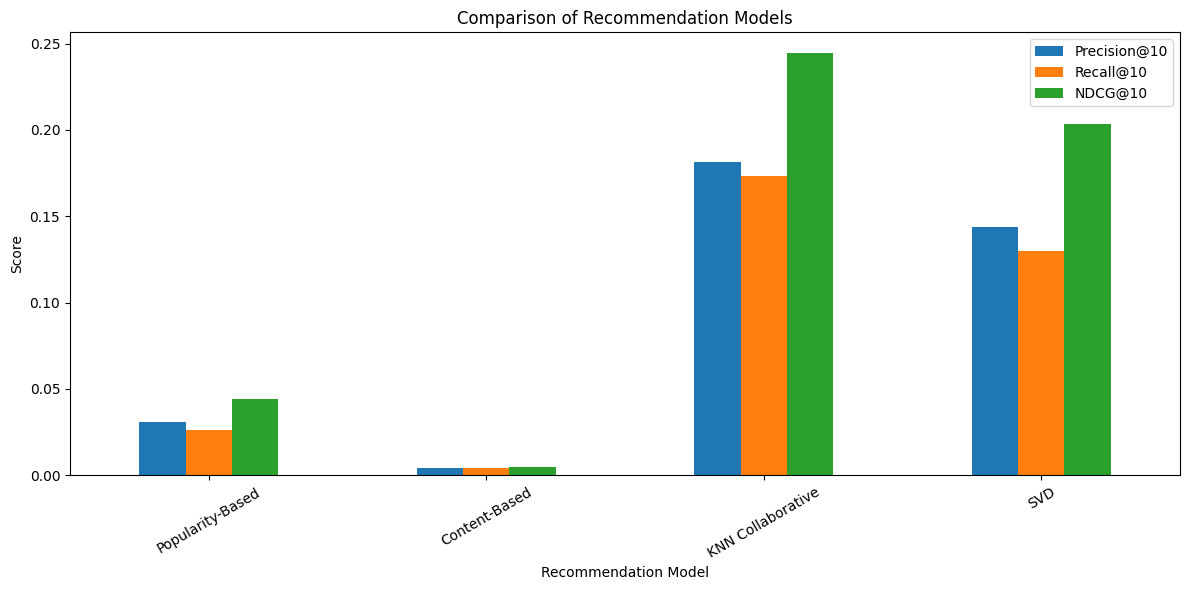

In [31]:
#Visualize ranking metrics
comparison_df.set_index("Model")[
    ["Precision@10", "Recall@10", "NDCG@10"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Recommendation Models")
plt.ylabel("Score")
plt.xlabel("Recommendation Model")

plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()

plt.show()

RMSE calculation

In [32]:
#Popularity-Based RMSE
global_rating_mean = ratings_train["rating"].mean()

popularity_rating_map = (
    popularity_stats.set_index("movieId")[
        "average_rating"
    ].to_dict()
)

popularity_predictions = ratings_test[
    "movieId"
].map(
    popularity_rating_map
).fillna(global_rating_mean)

popularity_predictions = popularity_predictions.clip(
    0.5, 5.0
)

popularity_rmse = np.sqrt(
    mean_squared_error(
        ratings_test["rating"],
        popularity_predictions
    )
)

print(
    "Popularity-Based RMSE:",
    round(popularity_rmse, 4)
)

Popularity-Based RMSE: 0.9827


In [33]:
#KNN RMSE
def knn_predict_rating(user_id, movie_id):

    movie_index = knn_movie_to_index[movie_id]

    user_ratings = user_movie_matrix.loc[user_id]

    weighted_sum = 0
    similarity_sum = 0

    for distance, neighbor_index in zip(
        knn_distances[movie_index],
        knn_indices[movie_index]
    ):

        neighbor_id = all_movie_ids[neighbor_index]

        if neighbor_id == movie_id:
            continue

        rating = user_ratings[neighbor_id]

        similarity = max(0, 1 - distance)

        if rating > 0 and similarity > 0:

            weighted_sum += similarity * rating
            similarity_sum += similarity

    if similarity_sum == 0:
        return global_rating_mean

    return weighted_sum / similarity_sum


knn_predictions = []

for row in ratings_test.itertuples(index=False):

    prediction = knn_predict_rating(
        row.userId,
        row.movieId
    )

    knn_predictions.append(prediction)

knn_predictions = np.clip(
    knn_predictions,
    0.5,
    5.0
)

knn_rmse = np.sqrt(
    mean_squared_error(
        ratings_test["rating"],
        knn_predictions
    )
)

print("KNN RMSE:", round(knn_rmse, 4))

KNN RMSE: 0.9985


In [34]:
#SVD RMSE
svd_predictions = []

for row in ratings_test.itertuples(index=False):

    user_index = user_to_index[row.userId]

    movie_index = movie_to_index[row.movieId]

    prediction = predicted_matrix[
        user_index,
        movie_index
    ]

    svd_predictions.append(prediction)

svd_predictions = np.clip(
    svd_predictions,
    0.5,
    5.0
)

svd_rmse = np.sqrt(
    mean_squared_error(
        ratings_test["rating"],
        svd_predictions
    )
)

print("SVD RMSE:", round(svd_rmse, 4))

SVD RMSE: 1.0108


,Model,RMSE
0,Popularity-Based,0.9827
1,KNN Collaborative,0.9985
2,SVD,1.0108


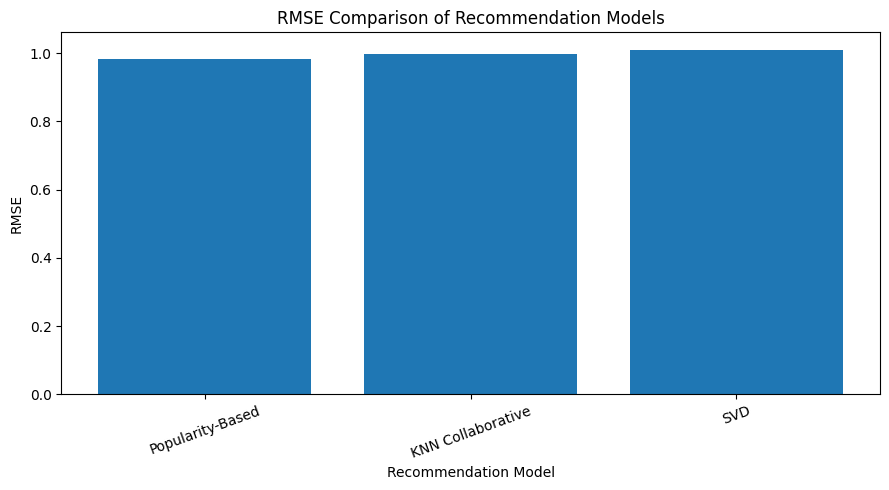

In [35]:
#Compare RMSE
rmse_results = pd.DataFrame({
    "Model": [
        "Popularity-Based",
        "KNN Collaborative",
        "SVD"
    ],
    "RMSE": [
        popularity_rmse,
        knn_rmse,
        svd_rmse
    ]
})

display(rmse_results.round(4))

plt.figure(figsize=(9, 5))

plt.bar(
    rmse_results["Model"],
    rmse_results["RMSE"]
)

plt.title("RMSE Comparison of Recommendation Models")
plt.xlabel("Recommendation Model")
plt.ylabel("RMSE")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

Interactive Movie Recommendation System

In [36]:
import ipywidgets as widgets
from IPython.display import display, clear_output

user_dropdown = widgets.Dropdown(
    options=all_users,
    description="User ID:"
)

model_dropdown = widgets.Dropdown(
    options=[
        "Popularity-Based",
        "Content-Based",
        "KNN Collaborative",
        "SVD"
    ],
    description="Model:"
)

number_dropdown = widgets.Dropdown(
    options=[5, 10, 15, 20],
    value=10,
    description="Movies:"
)

recommend_button = widgets.Button(
    description="Recommend Movies",
    button_style="success"
)

output = widgets.Output()


def show_recommendations(button):

    with output:

        clear_output()

        user_id = user_dropdown.value
        method = model_dropdown.value
        top_n = number_dropdown.value

        print("User ID:", user_id)
        print("Recommendation Method:", method)

        if method == "Popularity-Based":

            movie_ids = popularity_recommend_for_user(
                user_id, top_n
            )

        elif method == "Content-Based":

            movie_ids = content_recommend_for_user(
                user_id, top_n
            )

        elif method == "KNN Collaborative":

            movie_ids = knn_recommend_for_user(
                user_id, top_n
            )

        else:

            movie_ids = svd_recommend_for_user(
                user_id, top_n
            )

        if not movie_ids:
            print("No recommendations available.")
            return

        result = movies.set_index(
            "movieId"
        ).loc[movie_ids].reset_index()

        print("\nRecommended Movies:")

        display(
            result[["title", "genres"]]
        )


recommend_button.on_click(
    show_recommendations
)

display(
    widgets.VBox([
        user_dropdown,
        model_dropdown,
        number_dropdown,
        recommend_button,
        output
    ])
)

In [37]:
#Movie search interface
movie_input = widgets.Text(
    value="Toy Story",
    placeholder="Enter movie name",
    description="Movie:"
)

search_button = widgets.Button(
    description="Find Similar Movies",
    button_style="info"
)

search_output = widgets.Output()


def search_similar_movies(button):

    with search_output:

        clear_output()

        recommend_similar_movies(
            movie_input.value,
            top_n=10
        )


search_button.on_click(
    search_similar_movies
)

display(
    widgets.VBox([
        movie_input,
        search_button,
        search_output
    ])
)